# Hands-On Data Lab: Synthetic Retail Sales
A reproducible beginner-friendly analysis. Run all cells from top to bottom with the notebook working directory set to `notebooks/`. Data are simulated, not real transactions. Revenue is a calculated gross amount, not profit.

In [1]:
from pathlib import Path
import json, sys, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
assert (ROOT / 'data').is_dir(), 'Run from the project root or notebooks folder'
OUT = ROOT / 'outputs'; FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
print('Python:', sys.version.split()[0], '| platform:', platform.system())
for name, module in [('pandas',pd),('numpy',np),('matplotlib',__import__('matplotlib')),('seaborn',sns),('scikit-learn',sklearn)]:
    print(name, module.__version__)


Python: 3.13.16 | platform: Linux
pandas 2.2.3
numpy 2.3.5
matplotlib 3.10.9
seaborn 0.13.2
scikit-learn 1.6.1


## 1. Read and inspect
The CSV contains simulated transactions with deliberate quality issues. `head` previews rows, `info` shows types and missingness, `shape` gives dimensions, and `describe` summarizes numeric columns.

In [2]:
raw = pd.read_csv(ROOT / 'data' / 'synthetic_sales.csv')
print('Shape:', raw.shape)
print('First five rows:'); display(raw.head())
print('Column information:'); raw.info()
print('Numeric description:'); display(raw.describe())

Shape: (182, 5)
First five rows:


,transaction_id,date,category,units,unit_price_usd
0,T0001,2025-01-01,Electronics,6.0,80.0
1,T0002,2025-01-02,Clothing,6.0,30.0
2,T0003,2025-01-03,Electronics,2.0,80.0
3,T0004,2025-01-04,Clothing,6.0,30.0
4,T0005,2025-01-05,Accessories,NaN,15.0


Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 182 entries, 0 to 181
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  182 non-null    object 
 1   date            182 non-null    object 
 2   category        182 non-null    object 
 3   units           178 non-null    float64
 4   unit_price_usd  182 non-null    float64
dtypes: float64(2), object(3)
memory usage: 7.2+ KB
Numeric description:


,units,unit_price_usd
count,178.000000,182.000000
mean,3.421348,36.620879
std,1.812385,25.063107
min,1.000000,15.000000
25%,2.000000,15.000000
50%,3.000000,30.000000
75%,5.000000,30.000000
max,6.000000,80.000000


## 2. Data quality and cleaning
Count missing values and exact duplicate rows before changes. Remove exact duplicates first to avoid overweighting a repeated transaction. Fill missing units with the median within each category, then convert units to integer and dates to datetime. The assumption is that within-category median units are plausible; imputation reduces variability and is not ground truth.

In [3]:
missing = pd.DataFrame({'count':raw.isna().sum(), 'percent':raw.isna().mean().mul(100)})
duplicates = int(raw.duplicated().sum())
print('Exact duplicate rows:', duplicates); display(missing)
clean = raw.drop_duplicates().copy()
clean['date'] = pd.to_datetime(clean['date'], errors='raise')
clean['units'] = clean['units'].fillna(clean.groupby('category')['units'].transform('median'))
assert clean['units'].notna().all()
clean['units'] = clean['units'].round().astype(int)
clean['revenue_usd'] = (clean['units'] * clean['unit_price_usd']).round(2)
assert clean['transaction_id'].is_unique and not clean.isna().any().any()
clean.to_csv(OUT / 'cleaned_dataset.csv', index=False)
print('Clean shape:', clean.shape, '| remaining missing:', clean.isna().sum().sum())
display(clean.head())

Exact duplicate rows: 2


,count,percent
transaction_id,0,0.000000
date,0,0.000000
category,0,0.000000
units,4,2.197802
unit_price_usd,0,0.000000


Clean shape: (180, 6) | remaining missing: 0


,transaction_id,date,category,units,unit_price_usd,revenue_usd
0,T0001,2025-01-01,Electronics,6,80.0,480.0
1,T0002,2025-01-02,Clothing,6,30.0,180.0
2,T0003,2025-01-03,Electronics,2,80.0,160.0
3,T0004,2025-01-04,Clothing,6,30.0,180.0
4,T0005,2025-01-05,Accessories,4,15.0,60.0


## 3. Selection, filtering, sorting, aggregation, and merge
Selection narrows columns; filtering selects transactions; sorting ranks them. Grouping compares total gross revenue. The category table is a synthetic lookup, merged many-to-one to demonstrate enrichment without duplicating transactions.

In [4]:
print('Selected columns:'); display(clean.loc[:4, ['transaction_id','category','revenue_usd']])
print('High-value transactions (at least $200), highest first:')
display(clean.loc[clean['revenue_usd'] >= 200].sort_values('revenue_usd', ascending=False).head(5))
category_summary = clean.groupby('category', as_index=False).agg(transactions=('transaction_id','size'), units=('units','sum'), revenue_usd=('revenue_usd','sum')).sort_values('revenue_usd', ascending=False)
display(category_summary)
lookup = pd.DataFrame({'category':['Accessories','Clothing','Electronics'], 'department':['Lifestyle','Apparel','Technology']})
enriched = clean.merge(lookup, on='category', how='left', validate='many_to_one')
assert len(enriched)==len(clean) and enriched['department'].notna().all()
print('Lookup merge preview:'); display(enriched[['category','department']].head())

Selected columns:


,transaction_id,category,revenue_usd
0,T0001,Electronics,480.0
1,T0002,Clothing,180.0
2,T0003,Electronics,160.0
3,T0004,Clothing,180.0
4,T0005,Accessories,60.0


High-value transactions (at least $200), highest first:


,transaction_id,date,category,units,unit_price_usd,revenue_usd
0,T0001,2025-01-01,Electronics,6,80.0,480.0
22,T0023,2025-01-23,Electronics,6,80.0,480.0
131,T0132,2025-05-12,Electronics,6,80.0,480.0
116,T0117,2025-04-27,Electronics,6,80.0,480.0
138,T0139,2025-05-19,Electronics,6,80.0,480.0


,category,transactions,units,revenue_usd
2,Electronics,43,151,12080.0
1,Clothing,75,253,7590.0
0,Accessories,62,216,3240.0


Lookup merge preview:


,category,department
0,Electronics,Technology
1,Clothing,Apparel
2,Electronics,Technology
3,Clothing,Apparel
4,Accessories,Lifestyle


## 4. Descriptive statistics and outliers
For revenue x, mean = sum(x)/n; range = max − min; IQR = Q3 − Q1. Sample variance divides squared deviations by n−1; population variance divides by n. Standard deviation is the square root of variance. Quartiles use Pandas' linear interpolation. Pearson r measures linear association, not causation. Outliers lie strictly outside [Q1−1.5×IQR, Q3+1.5×IQR]; flags are not errors by themselves.

In [5]:
x = clean['revenue_usd']; q1=x.quantile(.25); q3=x.quantile(.75); iqr=q3-q1
lower=q1-1.5*iqr; upper=q3+1.5*iqr
flags=clean[(x<lower)|(x>upper)]
stats={'count':int(x.count()), 'mean':float(x.mean()), 'median':float(x.median()), 'modes':x.mode().tolist(), 'min':float(x.min()), 'max':float(x.max()), 'range':float(x.max()-x.min()), 'q1':float(q1), 'q3':float(q3), 'iqr':float(iqr), 'sample_variance':float(x.var(ddof=1)), 'population_variance':float(x.var(ddof=0)), 'sample_std':float(x.std(ddof=1)), 'population_std':float(x.std(ddof=0)), 'lower_fence':float(lower), 'upper_fence':float(upper), 'outliers':int(len(flags)), 'units_price_corr':float(clean['units'].corr(clean['unit_price_usd']))}
print('Revenue statistics (USD; variances in USD squared):'); display(pd.Series(stats))
print('Flagged rows:'); display(flags[['transaction_id','category','revenue_usd']])

Revenue statistics (USD; variances in USD squared):


count                           180
mean                     127.277778
median                         80.0
modes                        [60.0]
min                            15.0
max                           480.0
range                         465.0
q1                            56.25
q3                            160.0
iqr                          103.75
sample_variance         14540.03414
population_variance    14459.256173
sample_std               120.582064
population_std           120.246647
lower_fence                 -99.375
upper_fence                 315.625
outliers                         22
units_price_corr           0.013343
dtype: object

Flagged rows:


,transaction_id,category,revenue_usd
0,T0001,Electronics,480.0
5,T0006,Electronics,320.0
11,T0012,Electronics,320.0
22,T0023,Electronics,480.0
41,T0042,Electronics,400.0
45,T0046,Electronics,320.0
55,T0056,Electronics,400.0
63,T0064,Electronics,320.0
72,T0073,Electronics,400.0
100,T0101,Electronics,400.0


## 5. Visual exploration
The line chart aggregates by calendar month, not individual transactions. The heatmap includes revenue, which is mathematically derived from units and price; its correlations should not be interpreted as independent causal effects.

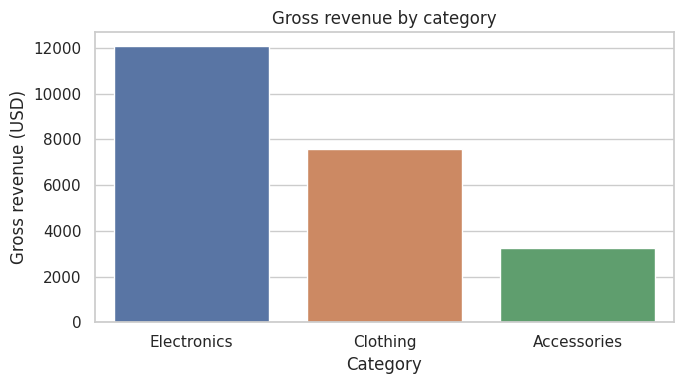

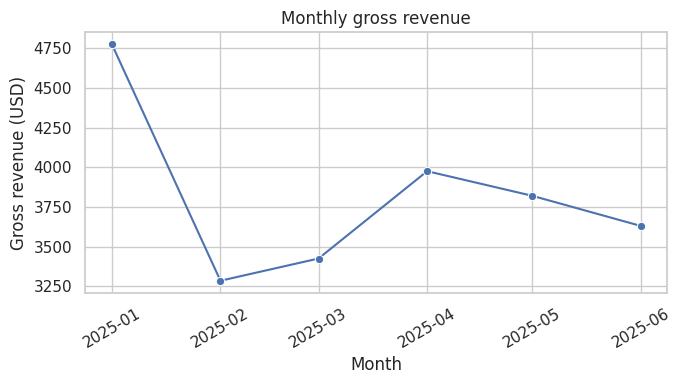

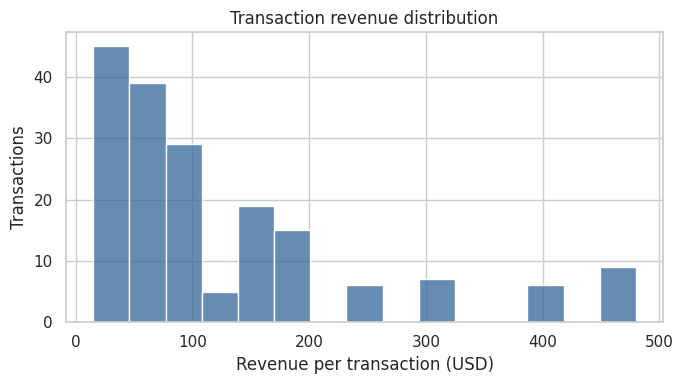

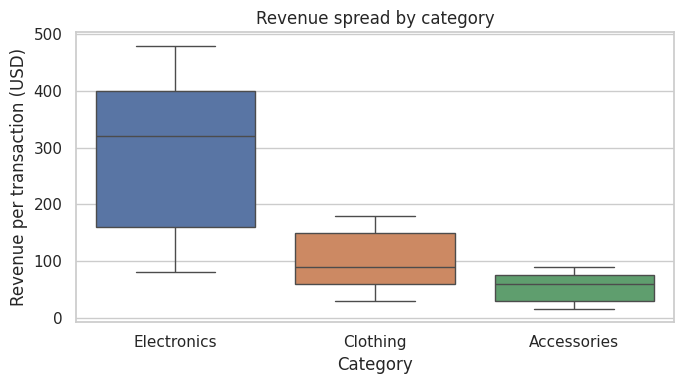

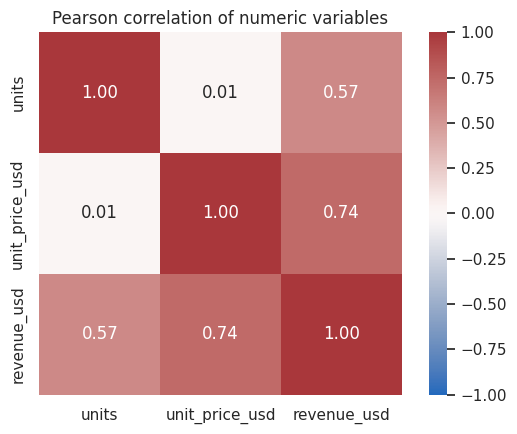

In [6]:
monthly=clean.assign(month=clean['date'].dt.to_period('M').dt.to_timestamp()).groupby('month',as_index=False)['revenue_usd'].sum()
def save(name):
    plt.tight_layout(); plt.savefig(FIG/name, dpi=160, bbox_inches='tight'); plt.show(); plt.close()
plt.figure(figsize=(7,4)); sns.barplot(data=category_summary,x='category',y='revenue_usd', hue='category', palette='deep', legend=False); plt.title('Gross revenue by category'); plt.xlabel('Category'); plt.ylabel('Gross revenue (USD)'); save('01_category_revenue.png')
plt.figure(figsize=(7,4)); sns.lineplot(data=monthly,x='month',y='revenue_usd',marker='o'); plt.title('Monthly gross revenue'); plt.xlabel('Month'); plt.ylabel('Gross revenue (USD)'); plt.xticks(rotation=30); save('02_monthly_revenue.png')
plt.figure(figsize=(7,4)); sns.histplot(x=clean['revenue_usd'],bins=15,color='#336699'); plt.title('Transaction revenue distribution'); plt.xlabel('Revenue per transaction (USD)'); plt.ylabel('Transactions'); save('03_revenue_histogram.png')
plt.figure(figsize=(7,4)); sns.boxplot(data=clean,x='category',y='revenue_usd',hue='category',palette='deep',legend=False); plt.title('Revenue spread by category'); plt.xlabel('Category'); plt.ylabel('Revenue per transaction (USD)'); save('04_category_boxplot.png')
plt.figure(figsize=(6,4.5)); corr=clean[['units','unit_price_usd','revenue_usd']].corr(); sns.heatmap(corr,annot=True,fmt='.2f',vmin=-1,vmax=1,cmap='vlag',square=True); plt.title('Pearson correlation of numeric variables'); save('05_correlation_heatmap.png')

## 6. Save auditable results
The JSON snapshot is generated from the same dataframe as the figures and the exported dataset. Use it to check report figures. Results are descriptive and apply only to this simulated dataset.

In [7]:
summary={'raw_shape':list(raw.shape),'clean_shape':list(clean.shape),'raw_types':{k:str(v) for k,v in raw.dtypes.items()},'clean_types':{k:str(v) for k,v in clean.dtypes.items()},'missing':{k:{'count':int(v['count']),'percent':float(v['percent'])} for k,v in missing.to_dict(orient='index').items()},'duplicates':duplicates,'stats':stats,'categories':category_summary.to_dict(orient='records'),'monthly':[{'month':r['month'].strftime('%Y-%m'),'revenue_usd':float(r['revenue_usd'])} for _,r in monthly.iterrows()],'versions':{'python':sys.version.split()[0],'pandas':pd.__version__,'numpy':np.__version__,'matplotlib':__import__('matplotlib').__version__,'seaborn':sns.__version__,'scikit-learn':sklearn.__version__}}
(OUT/'analysis_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print('Saved cleaned CSV, 5 figures, and analysis_summary.json to', OUT)

Saved cleaned CSV, 5 figures, and analysis_summary.json to /home/user/hands-on-data-lab-implementation/outputs
